# Radar to tune model
! need specific kernel

In [1]:
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage
import copy
from matplotlib import colors
import datetime
import cartopy.crs as ccrs
import cartopy
import wradlib
import pandas as pd
from glob import glob
import pyart
from matplotlib.ticker import NullFormatter

from svgpathtools import svg2paths
import matplotlib as mpl
from svgpath2mpl import parse_path

import sys
sys.path.append('/home/users/esree/dcmex_instruments/faam_data/')
# faam functions
from faam_data_functions import faam_mo_files, time_adjust, get_nc_variable, mask_data, flatten_20hz_variable, mo_mean, datetime_to_sec, cloud_pass_time



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
faam_mo_paths_dic = faam_mo_files() # dictionary containing dates + paths to nc files
sr1_base_loc = '/gws/ssde/j25a/dcmex/data/radar/grid/SR1_v3/' # ! version 3 !
sr1_date_list = os.listdir(sr1_base_loc)
sr1_date_list.sort() 
sr1_date_list.remove('20220716') # not flight day

## orography ## ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~
rasterfile = '/gws/ssde/j25a/dcmex/users/ezriab/radar_stuff/output_SRTMGL1.tif' # i have copied this file from David
ds = wradlib.io.open_raster(rasterfile) # wradlib - (radar meteorology library) open the raster file
rastervalues, rastercoords, raster_proj = wradlib.georef.extract_raster_dataset(ds, nodata=-32768.)
rastervalues_smooth = scipy.ndimage.median_filter(rastervalues, footprint=np.ones((5,5)))[::5, ::5]
lon = rastercoords[::5, ::5, 0]
lat = rastercoords[::5, ::5, 1] 
## ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ 
### dimond around mountain - lat lon coords
DC1 = (34.17, -107.18)
DC2 = (34.00, -107.00)
DC3 = (33.73, -107.18)
DC4 = (34.00, -107.37)

In [3]:
sr1_date = '20220730' # date of flight
date = sr1_date[2:]

In [4]:
day, core_phys_pth, faam_pth, mo_path = faam_mo_paths_dic[date]
faam_f = xr.open_mfdataset(faam_pth)
alt_unit, alt_longname, alt = get_nc_variable(faam_pth, 'ALT_GIN')

date_sr1_loc = f'{sr1_base_loc}20220730/'
sr1_file_list = glob(date_sr1_loc + '*2026v1*.nc')
sr1_file_names = [os.path.basename(file_path) for file_path in sr1_file_list]
sr1_file_names.sort()

In [5]:
t = '1715'
full_file_name = f'SL3D_grid_2026v1_{sr1_date}_{t}.nc'
full_file_path = date_sr1_loc + full_file_name
with xr.open_dataset(full_file_path) as grid:
    dbz = grid['DBZ'].isel(time=0) # just one time value, so remove this dimension
    vel = grid['VEL'].isel(time=0) # just one time value, so remove this dimension
    VT = grid['VT'].isel(time=0) # just one time value, so remove this dimension

In [6]:
grid

<xarray.Dataset> Size: 562MB
Dimensions:                     (time: 1, z: 71, y: 351, x: 351, nradar: 20)
Coordinates: (12/16)
  * time                        (time) datetime64[ns] 8B 2022-07-30T17:15:03....
  * z                           (z) float64 568B 1e+03 1.2e+03 ... 1.5e+04
    lat                         (y, x) float64 986kB ...
    lon                         (y, x) float64 986kB ...
  * y                           (y) float64 3kB -4.5e+04 -4.48e+04 ... 2.5e+04
  * x                           (x) float64 3kB -4e+04 -3.98e+04 ... 3e+04
    ...                          ...
    origin_altitude             (time) int64 8B ...
    radar_altitude              (nradar) float64 160B ...
    radar_latitude              (nradar) float64 160B ...
    radar_longitude             (nradar) float64 160B ...
    radar_time                  (nradar) float64 160B ...
    radar_name                  (nradar) <U3 240B ...
Dimensions without coordinates: nradar
Data variables: (12/15)
    KDP                         (time, z, y, x) float32 35MB ...
    VT                          (time, z, y, x) float32 35MB ...
    DT                          (time, z, y, x) float32 35MB ...
    VEL                         (time, z, y, x) float32 35MB ...
    DM                          (time, z, y, x) float32 35MB ...
    DZ                          (time, z, y, x) float32 35MB ...
    ...                          ...
    ZDR                         (time, z, y, x) float32 35MB ...
    PHIDP                       (time, z, y, x) float32 35MB ...
    DBZ                         (time, z, y, x) float32 35MB ...
    RHOHV                       (time, z, y, x) float32 35MB ...
    ROI                         (time, z, y, x) float32 35MB ...
    SL3D                        (time, z, y, x) float64 70MB ...
Attributes: (12/31)
    radar_name:           ['SR1', 'SR1', 'SR1', 'SR1', 'SR1', 'SR1', 'SR1', '...
    nradar:               20
    Conventions:          CF-1.7
    Sub_conventions:      CF-Radial instrument_parameters radar_parameters ra...
    version:              CF-Radial-1.4
    title:                R30_H12_V2
    ...                   ...
    n_gates_vary:         false
    ray_times_increase:   true
    volume_number:        9
    platform_type:        fixed
    instrument_type:      radar
    primary_axis:         axis_z

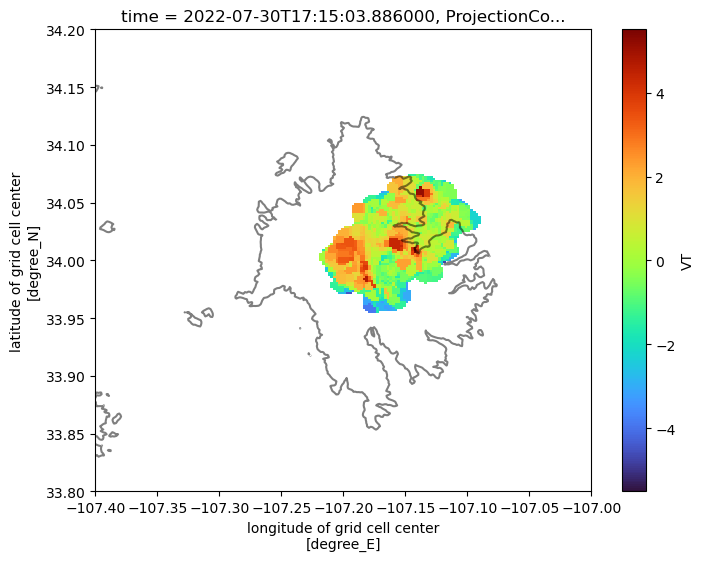

In [13]:
lon_max = -107.0
lon_min = -107.4
lat_max = 34.2
lat_min = 33.8
domain_mask = dbz.where((dbz.lon >= lon_min) & (dbz.lon <= lon_max) & (dbz.lat >= lat_min) & (dbz.lat <= lat_max))

dbz_masked = dbz.where(domain_mask.notnull()) # this is the masked data - only includes values in the domain
vel_masked = vel.where(domain_mask.notnull()) # this is the masked data - only includes values in the domain
vt_masked = VT.where(domain_mask.notnull()) # this is the masked data - only includes values in the domain

vel_masked_max = vel_masked.max(dim='z')
vt_masked_max = vt_masked.max(dim='z')

plt.figure(figsize=(8,6))
'''
vel_masked_max.plot(
    x='lon', y='lat',
    cmap='turbo',  # good for radar
    )#vmin=0, vmax=60)
'''
vt_masked_max.plot(
    x='lon', y='lat',
    cmap='turbo',  # good for radar
    )#vmin=0, vmax=60)

#plt.contour(rx0, ry0, rastervalues,cmap=plt.cm.gray,alpha=0.5, levels=[2250])
plt.contour(lon, lat, rastervalues_smooth,cmap=plt.cm.gray,alpha=0.5, levels=[2250])

#plt.title(f'Max column reflectivity (dBZ), SR1 {closest_time_str}')
plt.xlim(lon_min, lon_max)   # longitudes
plt.ylim(lat_min, lat_max)       # latitudes

plt.show()

In [9]:
vel_masked_max

<xarray.DataArray 'VEL' (y: 351, x: 351)> Size: 493kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(351, 351), dtype=float32)
Coordinates:
    time                        datetime64[ns] 8B 2022-07-30T17:15:03.886000
    lat                         (y, x) float64 986kB 33.57 33.57 ... 34.2 34.2
    lon                         (y, x) float64 986kB -107.6 -107.6 ... -106.9
  * y                           (y) float64 3kB -4.5e+04 -4.48e+04 ... 2.5e+04
  * x                           (x) float64 3kB -4e+04 -3.98e+04 ... 3e+04
    ProjectionCoordinateSystem  int32 4B 1
    projection                  int32 4B 1
    origin_latitude             float64 8B 33.98
    origin_longitude            float64 8B -107.2
    origin_altitude             int64 8B 0

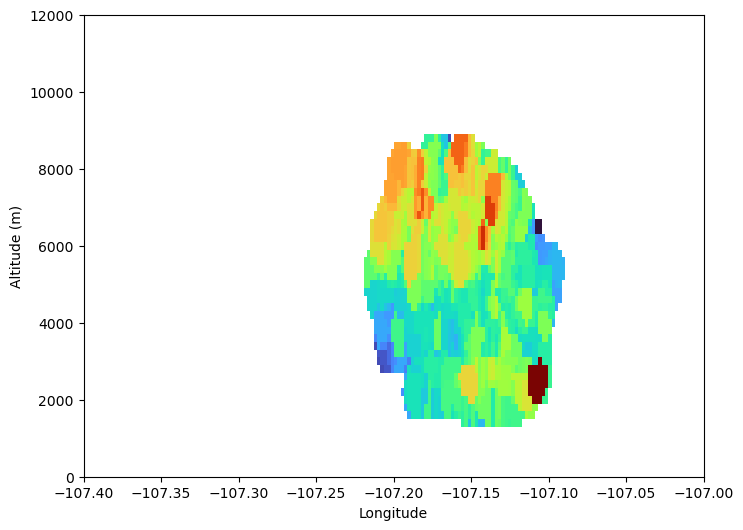

In [10]:
vel_max_lat = vel_masked.max(dim="y")
vel_lon_1d = vel_masked.lon.mean(dim="y")


plt.figure(figsize=(8,6))
plt.pcolormesh(
    vel_lon_1d,
    vel_max_lat.z,
    vel_max_lat,
    cmap='turbo')
'''
dbz_max.plot(
    x='lon', y='z',
    cmap='turbo',  # good for radar
    vmin=0, vmax=60)
'''
#plt.contour(rx0, ry0, rastervalues,cmap=plt.cm.gray,alpha=0.5, levels=[2250])
#plt.contour(lon_1d, lat, rastervalues_smooth,cmap=plt.cm.gray,alpha=0.5, levels=[2250])

#plt.title(f'Max column reflectivity (dBZ), SR1 {closest_time_str}')
plt.xlabel('Longitude')
plt.ylabel('Altitude (m)')
#plt.axis('equal')  # so x and y scales are consistent

plt.xlim(-107.4, -107.0)   # longitudes
plt.ylim(0, 12000)       # altitudes

plt.show()

In [ ]:
dbz_max_lon = dbz.max(dim="x")
lat_1d = dbz.lat.mean(dim="x")


plt.figure(figsize=(8,6))
plt.pcolormesh(
    lat_1d,
    dbz_max_lat.z,
    dbz_max_lat,
    cmap='turbo')
'''
dbz_max.plot(
    x='lon', y='z',
    cmap='turbo',  # good for radar
    vmin=0, vmax=60)
'''
#plt.contour(rx0, ry0, rastervalues,cmap=plt.cm.gray,alpha=0.5, levels=[2250])
#plt.contour(lon_1d, lat, rastervalues_smooth,cmap=plt.cm.gray,alpha=0.5, levels=[2250])

plt.title(f'Max column reflectivity (dBZ), SR1 {closest_time_str}')
plt.xlabel('Longitude')
plt.ylabel('Altitude (m)')
#plt.axis('equal')  # so x and y scales are consistent

#plt.xlim(-107.4, -107.0)   # longitudes
plt.xlim(33.8, 34.2)       # latitudes

plt.ylim(0, 12000)       # altitudes

plt.show()